# 🎨 Variasiyalı Avtoenkoderlər (Variational AutoEncoders - VAE)

## 🧥 FashionMNIST Verilənlər Dəsti üzərində Generativ Dərin Öyrənmə (Generative Deep Learning)

Bu dərsimizdə Müasir Süni İntellektin və Generativ Modellərin (*Generative AI*) ən zərif və təməl daşlarından biri olan **Variasiyalı Avtoenkoder (VAE - Variational AutoEncoder)** arxitekturasını addım-addım quracaq, öyrədəcək və tamamilə yeni süni geyim şəkilləri yaradacağıq!

---

### ❓ Klassik Avtoenkoder (Standard Autoencoder - AE) vs Variasiyalı Avtoenkoder (VAE): Əsas Fərq Nədir?

* **Klassik Avtoenkoder (Standard Autoencoder):**
  * Giriş şəklini sıxaraq gizli fəzada (*Latent Space*) sadəcə **tək bir diskret nöqtəyə (vektora)** çevirir.
  * Məqsədi yalnız şəkildən küyü təmizləmək (*Denoising*) və ya ölçünü sıxmaqdır (*Dimensionality Reduction*).
  * **Əsas çatışmazlığı:** Latent fəza kəsintili və xaotik olur; latent fəzadan təsadüfi bir koordinat seçib dekoderə verdikdə mənasız səs-küy yaranır. Çünki model paylanmanı deyil, sadəcə verilən konkret nöqtələri əzbərləyir!

* **Variasiyalı Avtoenkoder (VAE - Kingma & Welling, 2013):**
  * Şəkli tək bir koordinata deyil, **ehtimal paylanmasına (Probability Distribution)** çevirir!
  * Hər bir şəkil üçün iki parametr öyrənir: **Orta Qiymət ($\mu$ - Mean)** və **Dispersiya ($\sigma^2$ - Variance / Log-Variance)**.
  * **Möcüzə:** Latent fəza tamamilə **hamar, kəsilməz və nizamlı (Continuous & Smooth)** olur. Fəzanın istənilən nöqtəsindən təsadüfi koordinat götürdükdə model real həyatda mövcud olmayan, lakin tamamilə real görünən yeni və keyfiyyətli şəkillər sintez edə bilir!

---

### 📋 Notebook Əsas Mərhələləri:
1. 🔍 **FashionMNIST Məlumat Dəstinin Tədqiqi:** 10 geyim sinfi və ölçülər.
2. 🎲 **Xüsusi Nümunələmə Layı (Custom Sampling Layer):** Dərin Öyrənmənin ən məşhur həlli — *Reparameterization Trick (Yenidən Parametrləşdirmə Hiyləsi)*.
3. 🏗️ **Encoder və Decoder Modellərinin Qurulması:** Keras Functional API və Genişləndirici Konvolyusiya (*Conv2DTranspose*).
4. ⚖️ **İkili İtki Funksiyası (Dual Loss):** Bərpa İtkisi (*Reconstruction Loss*) və *KL Divergence (Kullback-Leibler İrqiləşməsi)*.
5. ⚙️ **Keras `train_step` Metodunun Aşılması (Custom Training Loop):** `tf.GradientTape()` ilə qradiyentlərin idarəsi.
6. 🚀 **VAE Modelinin Məşqi (Training):** İtki əyrilərinin monitorinqi.
7. 🎨 **Nəticələrin Tədqiqi və Generasiya:**
   * Latent fəzadan yeni geyimlərin yaradılması (*Image Synthesis*).
   * 256 ədəd tamamilə süni geyim kolleksiyasının sintezi.
   * Qeyri-nəzarətli Klasterləşdirmə (*Unsupervised Clustering*).

## ⚡ GPU Yoxlanışı (GPU Availability Check)

Qenerativ neyron şəbəkələri (VAE və GAN-lar) konvolyusiya və matris əməliyyatları ilə intensiv işlədiyi üçün təlim zamanı GPU-dan (Qrafik Prosessor) istifadə hesablama sürətini dəfələrlə artırır. Aşağıdakı kodla sistemdə aktiv GPU olub-olmadığını təsdiqləyirik.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras import layers

import os
import random
import numpy as np
from matplotlib import pyplot as plt

# Mövcud GPU-ların sayını yoxlayırıq (Confirm GPU is available)
gpus = tf.config.list_physical_devices('GPU')
print("Mövcud GPU-ların Sayı (Num GPUs Available):", len(gpus))
if gpus:
    print("Aktiv GPU cihazı:", gpus[0].name)
else:
    print("Diqqət: GPU tapılmadı, təlim CPU üzərində aparılacaq.")

Mövcud GPU-ların Sayı (Num GPUs Available): 0
Diqqət: GPU tapılmadı, təlim CPU üzərində aparılacaq.


## 🔒 Təkrarlana Bilən Nəticələr (Reproducibility & Random Seed)

Dərin öyrənmədə çəkilərin başlanğıc dəyərləri, məlumatların partiyalara (*batch*) bölünməsi və VAE-dəki təsadüfi nümunələmə əməliyyatları psevdo-təsadüfi ədədlərə əsaslanır. Hər işəsalmada eyni nəticələri əldə etmək və eksperimentləri sabit etmək üçün təsadüfilik toxumunu (*Random Seed*) sabitləyirik.

In [3]:
seed = 123
os.environ['PYTHONHASHSEED'] = str(seed)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'  # TF 2.0+ üçün deterministik əməliyyat bayrağı
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)
print(f"Bütün təsadüfilik toxumları (seeds) {seed} dəyərinə sabitləndi.")

Bütün təsadüfilik toxumları (seeds) 123 dəyərinə sabitləndi.


## 👗 FashionMNIST Verilənlər Dəstinin Tədqiqi

**FashionMNIST** — klassik əlyazma rəqəmləri MNIST bazasının müasir və daha çətin alternativdir. Zalando araşdırma mərkəzi tərəfindən yaradılmış bu baza 10 fərqli geyim və aksesuar növünün $28 \times 28$ ölçülü ağ-qara (*grayscale*) şəkillərindən ibarətdir.

### 🏷️ Kateqoriyalar və Etiketlər (Labels & Classes):

| Etiket (Label) | İngiliscə Adı | Azərbaycan dilində Mənası |
| :---: | :--- | :--- |
| **0** | T-shirt/top | Qısaqol köynək / Top |
| **1** | Trouser | Şalvar |
| **2** | Pullover | Cemper / Sviter |
| **3** | Dress | Don / Libas |
| **4** | Coat | Palto |
| **5** | Sandal | Səndəl |
| **6** | Shirt | Köynək |
| **7** | Sneaker | İdman ayaqqabısı (Krossovka) |
| **8** | Bag | Çanta |
| **9** | Ankle boot | Qısa boğazlı çəkmə |

### 📥 Məlumatın Yüklənməsi və Ölçülərin Təhlili

Keras kitabxanasından verilənləri birbaşa yükləyirik. Baza 60,000 təlim (*training*) və 10,000 sınaq (*test*) nümunəsindən ibarətdir. Hər bir şəkil $28 \times 28$ piksel ölçüsündədir.

In [5]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print(x_train.shape)
print(x_test.shape) 
print(y_train.shape)
print(y_test.shape) 

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


### 🖼️ Məlumatların Vizuallaşdırılması

Verilənlər bazasından təsadüfi 9 nümunə seçərək ekranda əks etdirək. Bu, şəkillərin keyfiyyəti və müxtəlif geyim formaları haqqında ilkin vizual təsəvvür yaradır.

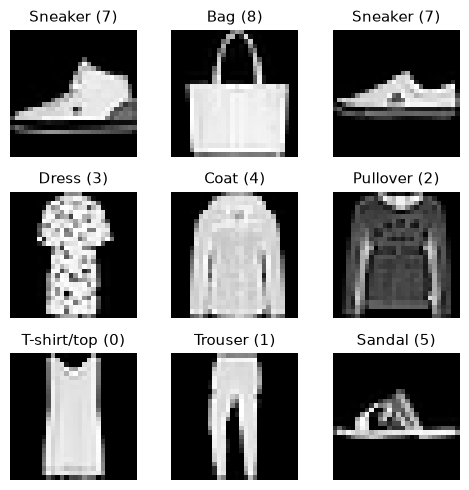

In [8]:
# 60,000 təlim nümunəsi arasından təsadüfi 9 ədədini seçirik
plt.figure(figsize=(5, 5))
rndSamples = np.random.choice(len(x_train), 9, replace=False)

# 10 sinfin adları lüğəti
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

for i in range(9):
    plt.subplot(3, 3, i + 1)
    idx = rndSamples[i]
    plt.imshow(x_train[idx], cmap="Greys_r")
    plt.title(f"{class_names[y_train[idx]]} ({y_train[idx]})", fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.show();

## ⚙️ Məlumatın Ön Emalı (Data Preprocessing)

Generativ modelləşdirməyə başlamazdan əvvəl məlumatları şəbəkənin tələblərinə uyğunlaşdırırıq:

1. **Train və Test Məlumatlarının Birləşdirilməsi:**  
   *Classification* modelin test dəqiqliyini ölçmək üçün Train və Test dəstləri ciddi şəkildə ayrılır. Lakin **Generativ Modellərdə** məqsəd sinfi təxmin etmək yox, ümumi paylanmanı öyrənib yeni şəkillər hasil etməkdir! Modelin keyfiyyəti təsnifat dəqiqliyi ilə deyil, vizual oxşarlıq və paylanma məsafəsi (*məsələn: FID - Frechet Inception Distance, IS - Inception Score*) ilə ölçülür. Buna görə də mümkün qədər zəngin müxtəliflik üçün 60,000 + 10,000 = **70,000 şəklin hamısını vahid massivdə birləşdiririk**.

2. **Piksellərin Normallaşdırılması (0 - 1 aralığı):**  
   Orijinal piksellər `0` (qara) ilə `255` (ağ) arasındadır. Dekoder modelimizin son çıxış layında `sigmoid` aktivasiya funksiyası istifadə olunacaq (çıxışı `[0, 1]` aralığındadır). Pikselləri `255.0`-ə bölərək `[0.0, 1.0]` diapazonuna miqyaslayırıq.

3. **Kanal Ölçüsünün Artırılması (`expand_dims`):**  
   Konvolyusiya layları (`Conv2D`, `Conv2DTranspose`) girişdə 3-ölçülü tensor gözləyir: `(Hündürlük, En, Kanallar)`. Ağ-qara şəkillərimiz `(28, 28)` olduğu üçün sonuna 1 kanal əlavə edərək `(28, 28, 1)` formasına salırıq.

In [9]:
# Train və Test massivlərini vahid böyük datasetdə birləşdiririk
dataset = np.concatenate([x_train, x_test], axis=0)
print("Birləşdirilmiş Dataset Ölçüsü:", dataset.shape)  # (70000, 28, 28)

Birləşdirilmiş Dataset Ölçüsü: (70000, 28, 28)


In [10]:
# expand_dims ilə kanal ölçüsü əlavə edirik: (28, 28) -> (28, 28, 1)
# və pikselləri 255-ə bölərək [0, 1] aralığına normallaşdırırıq
dataset = np.expand_dims(dataset, -1).astype("float32") / 255.0
print("Ön emaldan sonrakı yekun forma:", dataset.shape)
print("Minimum piksel:", dataset.min(), "| Maksimum piksel:", dataset.max())

Ön emaldan sonrakı yekun forma: (70000, 28, 28, 1)
Minimum piksel: 0.0 | Maksimum piksel: 1.0


## 🎲 Xüsusi Nümunələmə Layı: Reparameterization Trick (Yenidən Parametrləşdirmə Hiyləsi)

Bu hissə **Variasiyalı Avtoenkoderlərin (VAE) ən dahiyanə riyazi kəşfidir!**

### ⚠️ Problem Nə idi?
1. **Encoder** giriş şəklini ($X$) qəbul edir və gizli paylanmanın parametrlərini çıxarır: **Orta Qiymət ($\mu$ - Mean)** və **Loqarifmik Dispersiya ($\log(\sigma^2)$ - Log-Variance)**.
2. **Decoder** bu paylanmadan təsadüfi bir $z$ nöqtəsi seçərək (*Sampling: $z \sim \mathcal{N}(\mu, \sigma^2)$*) şəkli yenidən qurmalıdır.
3. **LAKİN BÖYÜK MANEƏ:** Təsadüfi seçim (*stochastic random sampling*) diferensiallana bilmir! Yəni onun riyazi törəməsi (*derivative*) yoxdur. Nəticədə xəta arxaya yayıla bilmir (**Backpropagation qırılır**) və şəbəkə çəkilərini yeniləyə bilmir!

---

### ✨ Həll: Reparameterization Trick (Kingma & Welling, 2013)
Təsadüfilik əməliyyatını neyron şəbəkəsinin əsas qradiyent axınından kənara çıxarırıq:
$$z = \mu + \sigma \odot \epsilon$$

Burada:
* $\epsilon$ — Standart Normal Paylanmadan götürülən təsadüfi səs-küydür: $\epsilon \sim \mathcal{N}(0, I)$.
* $\mu$ və $\sigma$ — Neyron şəbəkəsinin birbaşa idarə etdiyi, diferensiallanan deterministik çəkilərdir!
* Riyazi dayanıqlılıq üçün $\sigma$ birbaşa deyil, $\log(\sigma^2)$ kimi öyrənilir:
  $$\sigma = \exp\left(0.5 \cdot \log(\sigma^2)\right)$$
* Beləliklə: $z = \text{zMean} + \exp(0.5 \cdot \text{zLogVar}) \cdot \epsilon$

Bu bərabərlik sayəsində qradiyent heç bir maneə olmadan $\mu$ və $\sigma$ üzərindən Encoder-ə rahatlıqla axır və model uğurla təlim olunur!

In [11]:
# Xüsusi Nümunələmə Layı (Custom Sampling Layer)
class SamplingLayer(layers.Layer):
    # Reparameterization Trick: z = mu + sigma * epsilon
    # Təsadüfi səs-küyü (epsilon) kənardan daxil edərək əməliyyatı diferensiallanan edir.
    def call(self, inputs):
        zMean, zLogVar = inputs
        batch = tf.shape(zMean)[0]
        dim = tf.shape(zMean)[1]
        
        # Standart Normal Paylanmadan (mean=0, std=1) təsadüfi epsilon götürürük
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
        
        # z = mu + exp(0.5 * log_var) * epsilon
        return zMean + tf.exp(0.5 * zLogVar) * epsilon

## 🏗️ Encoder (Kodlaşdırıcı) Arxitekturası

Encoder şəkli qəbul edir və onu 2D gizli fəzada (*Latent Space*, `latentDim = 2`) ehtimal paylanması parametrlərinə çevirir.

Biz Keras-ın **Functional API** mexanizmindən istifadə edirik, çünki bu model xətti/ardıcıl (*Sequential*) deyil: konvolyusiya blokundan sonra eyni anda paralel iki çıxış hasil etməlidir:
1. `zMean` ($\mu$): Paylanmanın mərkəz nöqtəsi (orta qiymət).
2. `zLogVar` ($\log(\sigma^2)$): Paylanmanın yayılma dərəcəsi (dispersiya).

Sonda bu iki çıxış bizim yaratdığımız `SamplingLayer`-ə ötürülür və yekun $z$ vektoru nümunələnir.

In [12]:
def buildEncoder(latentDim, encoderInputs):
    # Giriş şəkillərindən xüsusiyyətləri çıxaran konvolyusiya bloku
    conv_block = keras.models.Sequential([
        layers.Conv2D(128, 3, activation="relu", strides=2, padding="same"),  # 28x28 -> 14x14
        layers.Conv2D(64, 3, activation="relu", strides=2, padding="same"),   # 14x14 -> 7x7
        layers.Flatten(),
        layers.Dense(256, activation="relu")
    ], name="encoder_conv_block")

    # Girişi konvolyusiya blokundan keçiririk
    x = conv_block(encoderInputs)

    # Paralel iki çıxış layı:
    # 1. zMean (orta qiymət / mu)
    zMean = layers.Dense(latentDim, name="z_mean")(x)
    # 2. zLogVar (loqarifmik dispersiya / log_variance)
    zLogVar = layers.Dense(latentDim, name="z_log_var")(x)

    # Reparameterization layı vasitəsilə z nöqtəsini nümunələyirik
    z = SamplingLayer(name="sampling_layer")([zMean, zLogVar])

    # Model 3 dəyər qaytarır: zMean, zLogVar və z
    return keras.Model(encoderInputs, [zMean, zLogVar, z], name="encoder")


# Encoder modelini 2-ölçülü latent fəza üçün qururuq
encoderInputs = keras.Input(shape=(28, 28, 1), name="encoder_input")
encoder = buildEncoder(latentDim=2, encoderInputs=encoderInputs)
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_conv_block  │ (None, 256)       │    878,144 │ encoder_input[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        514 │ encoder_conv_blo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        514 │ encoder_conv_blo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_layer      │ (None, 2)         │          0 │ z_mean[0][0],     │
│ (SamplingLayer)     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 879,172 (3.35 MB)

 Trainable params: 879,172 (3.35 MB)

 Non-trainable params: 0 (0.00 B)

## 🎨 Decoder (Dekodlaşdırıcı / Bərpaçı) Arxitekturası

Decoder Encoder-in tam əksini icra edir: 2-ölçülü kiçik latent koordinatdan ($z$) başlayaraq addım-addım $28 \times 28$ ölçülü tam detalizasiyalı şəkil bərpa edir.

### 🔍 Əsas Texnoloji Fərq: `Conv2DTranspose` (Genişləndirici / Tərs Konvolyusiya)
* Adi `Conv2D` böyük şəkli süzərək ölçünü kiçildirdi ($28 \times 28 \to 14 \times 14 \to 7 \times 7$).
* `Conv2DTranspose` (bəzən *Deconvolution* adlanır) isə əksinə — kiçik xüsusiyyət xəritələrini addım-addım genişləndirərək böyüdür ($7 \times 7 \to 14 \times 14 \to 28 \times 28$).
* Son qatda 1 filtr və `sigmoid` aktivasiyası istifadə edirik ki, hasil edilən piksellər orijinal şəkillər kimi `[0, 1]` aralığında olsun.

In [13]:
def buildDecoder(latentInputs):
    # 2D latent vektordan başlayaraq 28x28x1 şəkli bərpa edən arxitektura
    decoder_block = keras.models.Sequential([
        # Latent vektoru 7*7*64 = 3136 ölçülü fəzaya proyeksiya edirik
        layers.Dense(7 * 7 * 64, activation="relu", input_shape=(latentInputs.shape[1],)),
        layers.Reshape((7, 7, 64)),
        # Genişləndirici konvolyusiyalar (Upsampling via Conv2DTranspose)
        layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same"),  # 7x7 -> 14x14
        layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same"),   # 14x14 -> 28x28
        # Çıxış qatı: 1 kanal, piksel ehtimalları [0, 1] üçün sigmoid aktivasiyası
        layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")             # 28x28x1
    ], name="decoder_block")

    return keras.Model(latentInputs, decoder_block(latentInputs), name="decoder")


# Decoder modelini qururuq
latentInputs = keras.Input(shape=(2,), name="decoder_input")
decoder = buildDecoder(latentInputs)
decoder.summary()

c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\tf_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block (Sequential)      │ (None, 28, 28, 1)      │       157,633 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,633 (615.75 KB)

 Trainable params: 157,633 (615.75 KB)

 Non-trainable params: 0 (0.00 B)

## ⚖️ İtki Funksiyaları (Loss Functions): İkili Balans

VAE-nin öyrənməsi **iki fərqli itki funksiyasının rəqabəti və balansı** üzərində qurulub:
$$\text{Total Loss} = \text{Reconstruction Loss} + \alpha \cdot \text{KL Divergence Loss}$$

---

### 1️⃣ Bərpa İtkisi (Reconstruction Loss)
Dekoderin bərpa etdiyi şəkillə orijinal şəklin piksel-piksel oxşarlığını ölçür.
* Burada **Binary Cross-Entropy (BCE)** istifadə olunur (piksellər 0 ilə 1 arasında ehtimal kimi qəbul edilir).
* Əgər dekoder orijinaldan fərqli şəkil hasil edərsə, bu itki yüksəlir və modeli pikselləri daha dəqiq çəkməyə məcbur edir.

In [14]:
# 1. Bərpa İtkisi (Reconstruction Loss - Binary Cross-Entropy)
def reconstructionLoss(data, reconstructed):
    # Hər piksel üçün xətaları toplayır və partiya üzrə orta qiymətini tapır
    return tf.reduce_mean(
        tf.reduce_sum(
            keras.losses.binary_crossentropy(data, reconstructed),
            axis=(1, 2)
        )
    )

### 2️⃣ Kullback-Leibler İrqiləşməsi (KL Divergence Loss)

Bu itki funksiyası iki ehtimal paylanması arasındakı məsafəni/fərqi ölçür.

* **Niyə lazımdır?**  
  Əgər yalnız Reconstruction Loss olsa idi, model latent fəzada hər sinfi bir küncə atıb aralarında nəhəng boşluqlar qoyardı (klassik avtoenkoder kimi).
* **KL Divergence-in Vəzifəsi:**  
  Modeli məcbur edir ki, öyrəndiyi bütün latent paylanmalar **Standart Normal Paylanmaya ($\mathcal{N}(0, I)$)** yaxın olsun (orta qiymət $\mu \approx 0$, dispersiya $\sigma \approx 1$).
* **Fiziki / Geometrik Nəticə:**  
  Bütün geyimlərin latent koordinatları koordinat başlanğıcı (0,0) ətrafında sıx, hamar və bütöv bir duman kimi cəmləşir. Beləliklə, fəzada heç bir "boşluq" qalmır və istənilən nöqtədən mənalı şəkil hasil etmək mümkün olur!

> 💡 **Analogiya:** Bəzən buna *Earth Mover Distance* analogiyası ilə baxılır — bir paylanmanı digərinin şəklinə salmaq üçün nə qədər "torpaq qazıb daşımaq" lazım olduğunu ifadə edir.

In [15]:
# 2. KL Divergence İtkisi (Kullback-Leibler Divergence)
# Analitik düstur: KL( q(z|x) || N(0, I) ) = -0.5 * sum(1 + log(sigma^2) - mu^2 - sigma^2)
def klDivergenceLoss(zMean, zLogVar):
    return tf.reduce_mean(
        tf.reduce_sum(
            -0.5 * (1 + zLogVar - tf.square(zMean) - tf.exp(zLogVar)),
            axis=1
        )
    )

### 3️⃣ Ümumi İtki (Total Loss) və KL Çəkisi ($\beta$-VAE)

Hər iki itki cəmlənir. KL itkisinin qarşısındakı çəki əmsalı (`klWeight = 3.0`) vacib bir tənzimləmə (*tuning*) hiperparametrdir:
* Əgər çəki çox kiçik olsa: Model paylanmanı unudar, sadəcə pikselləri bərpa edər (qenerativlik zəifləyər).
* Əgər çəki çox böyük olsa: Bütün şəkillər bir-birinə qarışar, bərpa dumanlı və bulanıq olar.
* `klWeight = 3.0` bərpa dəqiqliyi ilə latent fəzanın nizamlılığı arasında ideal kompromisdir.

In [18]:
# 3. Yekun İtkinin Hesablanması (Total Loss)
def calcTotalLoss(data, reconstructed, zMean, zLogVar):
    loss1 = reconstructionLoss(data, reconstructed)
    loss2 = klDivergenceLoss(zMean, zLogVar)
    klWeight = 3.0  # KL itkisinin çəkisi (alpha / beta hiperparametri)
    totalLoss = loss1 + klWeight * loss2
    return loss1, loss2, totalLoss

## ⚙️ Keras `train_step` Metodunun Aşılması (Custom Training Loop)

Standart Keras modellərində `fit()` metodu tək bir giriş və tək bir itki gözləyir. Lakin bizim modelimizdə:
* Həm orijinal giriş şəkilləri ($X$), həm bərpa edilmiş şəkillər ($\hat{X}$),
* Həm də gizli layın daxili parametrləri ($\mu$ və $\sigma$) eyni anda itki hesablanmasında iştirak edir!

Buna görə `keras.Model` sinfindən miras alaraq **`train_step` metodunu yenidən yazırıq (override edirik)**. `tf.GradientTape()` arxaya yayılmanı avtomatik lentə alır, törəmələri tapır və `Adam` optimizatoru vasitəsilə çəkiləri yeniləyir.

In [16]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        # İtkiləri təlim tarixçəsində izləmək üçün metrik izləyicilər (Metric Trackers)
        self.totalLossTracker = keras.metrics.Mean(name="total_loss")
        self.ceLossTracker = keras.metrics.Mean(name="ce_loss")
        self.klLossTracker = keras.metrics.Mean(name="kl_loss")
    
    @property
    def metrics(self):
        # Modelin izlədiyi bütün metrikaların siyahısı
        return [
            self.totalLossTracker,
            self.ceLossTracker,
            self.klLossTracker
        ]

    # Hər təlim partiyasında (batch) icra olunan addım
    def train_step(self, data):
        # GradientTape - çəkilərin yenilənməsi üçün bütün əməliyyatları lentə alır
        with tf.GradientTape() as tape:
            # 1. İrəli Yayılma (Forward Pass)
            zMean, zLogVar, z = self.encoder(data)
            reconstruction = self.decoder(z)
            # 2. Xətaların Hesablanması
            ceLoss, klLoss, totalLoss = calcTotalLoss(data, reconstruction, zMean, zLogVar)

        # 3. Geri Yayılma (Backward Pass): Qradiyentləri tapırıq
        grads = tape.gradient(totalLoss, self.trainable_weights)
        # 4. Optimizator çəkiləri yeniləyir
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # 5. İtkilərin cari vəziyyətini yeniləyirik
        self.totalLossTracker.update_state(totalLoss)
        self.ceLossTracker.update_state(ceLoss)
        self.klLossTracker.update_state(klLoss)

        # Monitorinq üçün nəticələri qaytarırıq
        return {
            "total_loss": self.totalLossTracker.result(),
            "ce_loss": self.ceLossTracker.result(),
            "kl_loss": self.klLossTracker.result()
        }

## 🚀 VAE Modelinin Məşqi (Training the VAE)

Modelimizi `Adam` optimizatoru və `learning_rate = 0.001` ilə tərtib edib (*compile*), 70,000 şəkildən ibarət dataset üzərində 30 epox ərzində 128 ölçülü partiyalarla (*batch size*) məşq etdiririk.

In [19]:
# VAE obyektini yaradırıq və tərtib edirik
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001))

# Modeli 30 epox təlim edirik
history = vae.fit(dataset, epochs=30, batch_size=128)

Epoch 1/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - ce_loss: 301.8314 - kl_loss: 3.7628 - total_loss: 313.1199
Epoch 2/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - ce_loss: 266.1147 - kl_loss: 4.5356 - total_loss: 279.7213
Epoch 3/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - ce_loss: 262.8530 - kl_loss: 4.6682 - total_loss: 276.8576
Epoch 4/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - ce_loss: 261.1050 - kl_loss: 4.7420 - total_loss: 275.3309
Epoch 5/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - ce_loss: 259.7975 - kl_loss: 4.8110 - total_loss: 274.2303
Epoch 6/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - ce_loss: 258.8096 - kl_loss: 4.8709 - total_loss: 273.4224
Epoch 7/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 23s 42ms/step - ce_loss: 257.9648 - kl_loss: 4.9226 - total_loss: 272.7325
Epoch 8/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 22s 40ms/step - ce_loss: 257.2149 - kl_loss: 4.9646 - total_loss: 272.1086
Epoch 9/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 23s 42ms/step - ce_loss: 256.6581 - kl_l

## 📊 Təlim İtkilərinin Dinamikası (Loss Curves Visualization)

Hər epox üzrə Ümumi İtki (*Total Loss*), Bərpa İtkisi (*Reconstruction Loss*) və KL İtkisinin (*KL Loss*) necə azaldığını qrafikdə əks etdirək. Bu, modelin sabit öyrəndiyini və konvergensiyasını yoxlamağa kömək edir.

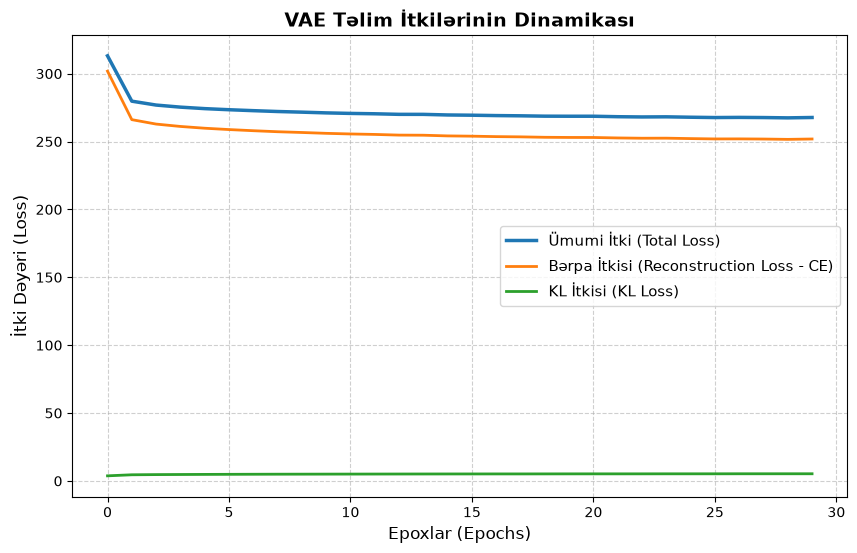

In [20]:
# İtkilərin epoxlar üzrə dəyişmə qrafiki
plt.figure(figsize=(10, 6))
plt.plot(history.history.get('total_loss'), label="Ümumi İtki (Total Loss)", linewidth=2.5)
plt.plot(history.history.get('ce_loss'), label="Bərpa İtkisi (Reconstruction Loss - CE)", linewidth=2)
plt.plot(history.history.get('kl_loss'), label="KL İtkisi (KL Loss)", linewidth=2)
plt.title("VAE Təlim İtkilərinin Dinamikası", fontsize=14, fontweight="bold")
plt.xlabel("Epoxlar (Epochs)", fontsize=12)
plt.ylabel("İtki Dəyəri (Loss)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.show();

### 🔍 KL İtkisinin Yaxından Təhlili

KL itkisi bərpa itkisi ilə müqayisədə rəqəmsal olaraq daha kiçik miqyasda olduğuna görə, onun trayektoriyasını daha aydın görmək üçün ayrıca böyüdülmüş qrafikdə əks etdiririk.

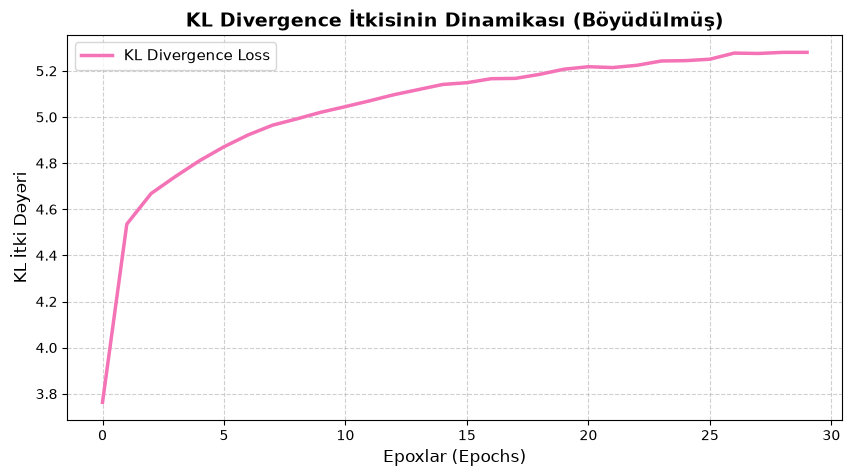

In [21]:
# KL İtkisinin ayrılmış qrafiki
plt.figure(figsize=(10, 5))
plt.plot(history.history.get('kl_loss'), color="#f472b6", label="KL Divergence Loss", linewidth=2.5)
plt.title("KL Divergence İtkisinin Dinamikası (Böyüdülmüş)", fontsize=14, fontweight="bold")
plt.xlabel("Epoxlar (Epochs)", fontsize=12)
plt.ylabel("KL İtki Dəyəri", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.show();

# 🎨 Nəticələrin Tədqiqi və Yeni Şəkillərin Yaradılması (Image Generation)

İndi isə VAE-nin ən maraqlı mərhələsinə gəlirik: **Süni İntellektlə Şəkil Sintezi!**

Biz təlim olunmuş VAE modelinin **yalnız Dekoder (Decoder) hissəsini götürürük**. Ona 2D latent fəzadan ixtiyari iki rəqəm verəcəyik və model həmin koordinatlardan yeni bir geyim şəkli çəkəcək.

İlk olaraq latent fəzada mərkəz nöqtəsi olaraq $\mu_0 = 1$ və $\mu_1 = 2$ koordinatını verib nəticəyə baxaq. Siz bu ədədləri dəyişərək (məsələn, `[-2, 1]`, `[0, -1]`, `[2, 3]`) fərqli geyimlər (don, çanta, köynək, ayaqqabı) sintez edə bilərsiniz!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


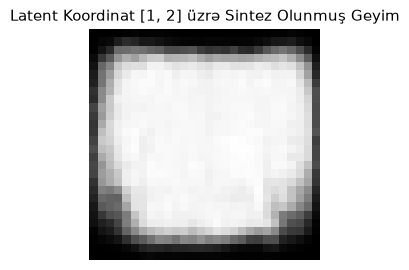

In [39]:
# Koordinat [1, 2] nöqtəsindən süni şəkil sintez edirik
test_latent_point = np.array([[1.0, 2.0]])
synth = vae.decoder.predict(test_latent_point)

plt.figure(figsize=(3, 3))
plt.imshow(synth.reshape((28, 28)), cmap="Greys_r")
plt.title("Latent Koordinat [1, 2] üzrə Sintez Olunmuş Geyim", fontsize=11)
plt.axis('off')
plt.show();

### 🎲 256 Ədəd Tamamilə Təsadüfi Yeni Geyim Şəklinin Sintezi

İndi isə 2-ölçülü normal paylanmadan tamamilə təsadüfi **256 ədəd koordinat cütü** seçək ($256 \times 2$ ölçülü tenzor).

Dekoder bu 256 təsadüfi nöqtəni emal edəcək və heç vaxt real dünyada mövcud olmayan 256 fərqli geyim növü hasil edəcək! Nəticəni $16 \times 16$ tor şəklində vizuallaşdırırıq.

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


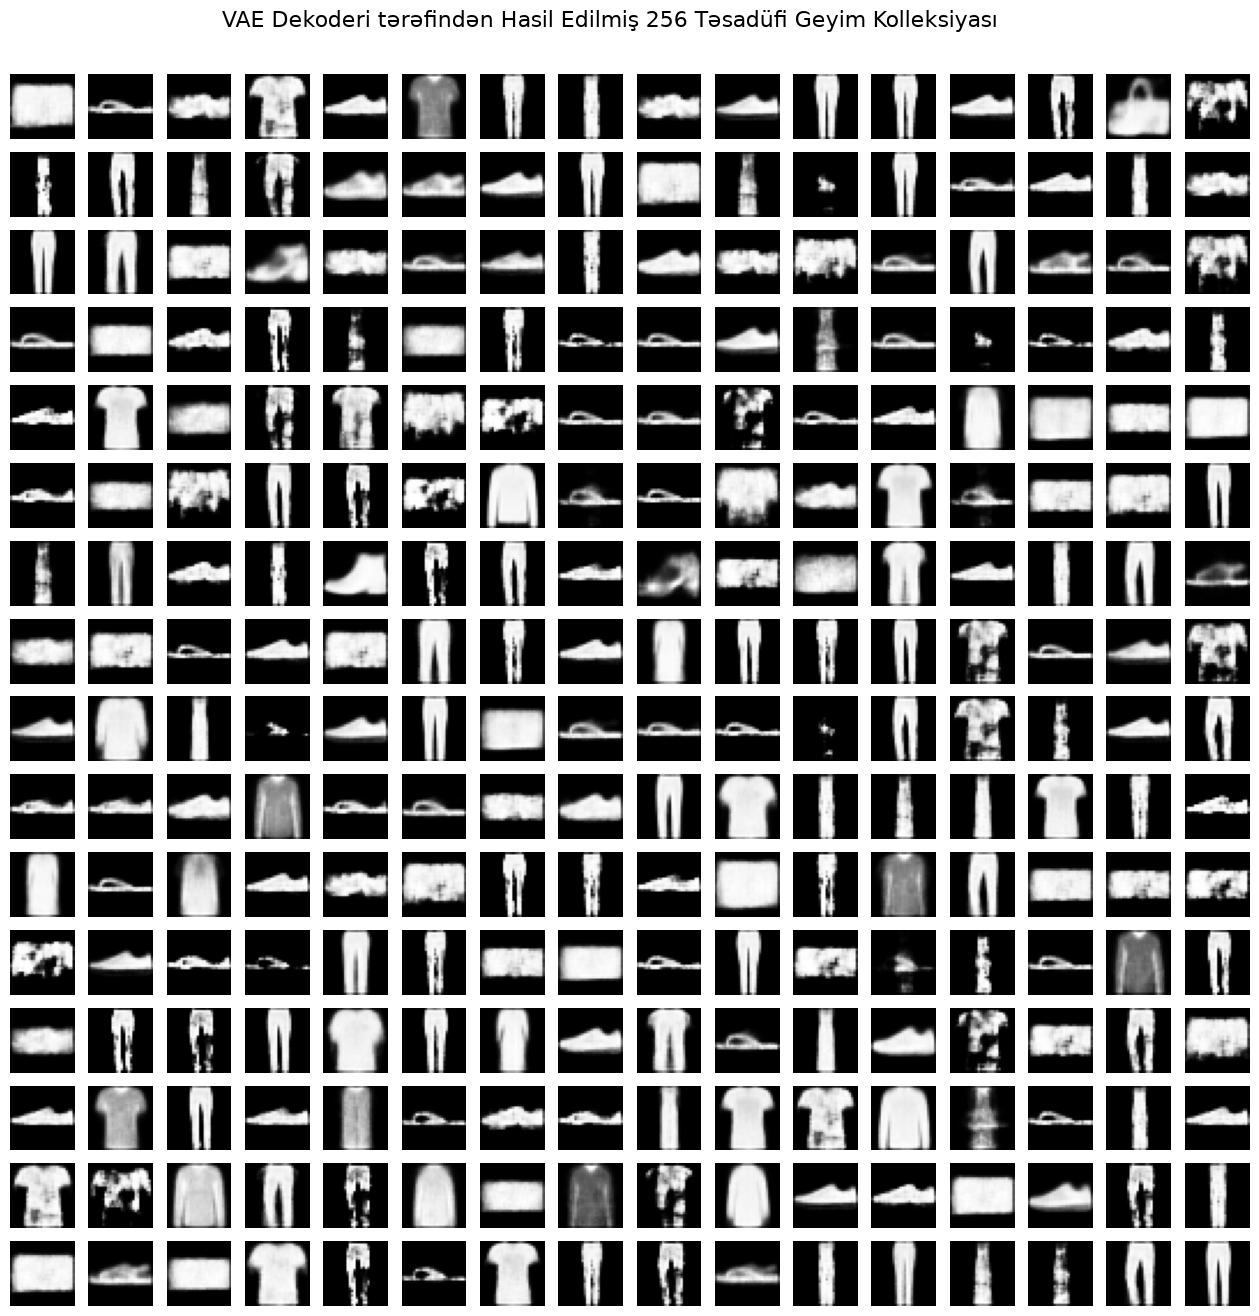

In [40]:
# Standart normal paylanmadan (loc=0, scale=4) 256 təsadüfi latent nöqtə seçirik
z = np.random.normal(loc=0, scale=4, size=(256, 2))
synth = vae.decoder.predict(z)

plt.figure(figsize=(16, 16))
for i in range(256):
    plt.subplot(16, 16, i + 1)
    plt.imshow(synth[i].reshape((28, 28)), cmap="Greys_r")
    plt.axis('off')

plt.suptitle("VAE Dekoderi tərəfindən Hasil Edilmiş 256 Təsadüfi Geyim Kolleksiyası", fontsize=16, y=0.92)
plt.show();

## 🎯 Şəkildən Latent Koda və Geri Bərpa (Reconstruction & Mapping)

Müəyyən bir geyim növünü (məsələn, xüsusi bir çantanı və ya ayaqqabını) sifarişlə hasil etmək istəsək nə etməliyik?
1. O kateqoriyaya aid real bir şəkli **Encoder**-ə veririk.
2. Encoder həmin şəklin latent məkandakı dəqiq koordinatını ($z$) çıxarır.
3. Sonra bu $z$ vektorunu **Decoder**-ə ötürərək həmin kateqoriyadan bənzər şəkil sintez etdiririk!

> 💡 **Qeyd:** Əgər şəkli birbaşa istədiyimiz sinif etiketi ilə (məsələn: *"Mənə 'don' şəkli ver"*) hasil etmək istəyiriksə, bu yanaşmanın təkmilləşdirilmiş növü olan **Şərti Variasiyalı Avtoenkoderlər (Conditional VAE - CVAE)** tətbiq olunur.

In [41]:
idx = 1280
# 1280-ci nümunəni götürürük və formatlayırıq
batch = np.expand_dims(x_train[idx], axis=0)
batchOfImages = np.expand_dims(batch, axis=-1).astype("float32") / 255.0
print("Giriş şəklinin forması:", batchOfImages.shape)

# Şəklin latent fəzadakı parametrini (zMean, zLogVar, z) əldə edirik
_, _, z = vae.encoder.predict(batchOfImages)
print("Encoder-in tapdığı 2D latent koordinat (z):", z)

# Dekoderə həmin z koordinatını verib oxşar şəkil bərpa edirik
synth = vae.decoder.predict([z])

Giriş şəklinin forması: (1, 28, 28, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Encoder-in tapdığı 2D latent koordinat (z): [[-1.3629956   0.07515254]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\tf_env\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: decoder_input
Received: inputs=('Tensor(shape=(1, 2))',)
  warnings.warn(msg)


### 🔄 Orijinal Şəkil və Bərpa Edilmiş Şəklin Yan-yana Müqayisəsi

Seçilmiş indeksli orijinal şəkillə VAE-nin sıxıb yenidən qurduğu şəkli yan-yana müqayisə edək. Modelin əsas formanı necə qoruduğunu, lakin bəzi incə detalları bir qədər hamarlaşdırdığını görə bilərsiniz.

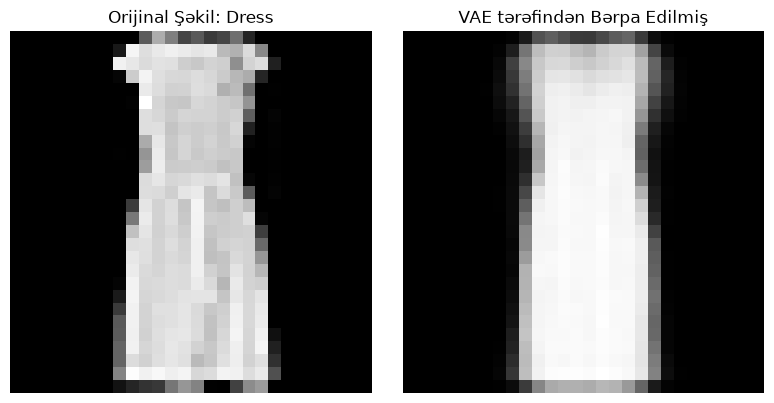

In [42]:
plt.figure(figsize=(8, 4))

# 1. Orijinal Şəkil
plt.subplot(1, 2, 1)
plt.imshow(x_train[idx], cmap="Greys_r")
plt.title(f"Orijinal Şəkil: {class_names[y_train[idx]]}", fontsize=12)
plt.axis('off')

# 2. VAE tərəfindən bərpa edilmiş şəkil
plt.subplot(1, 2, 2)
plt.imshow(synth[0].reshape((28, 28)), cmap="Greys_r")
plt.title("VAE tərəfindən Bərpa Edilmiş", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show();

2188/2188 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


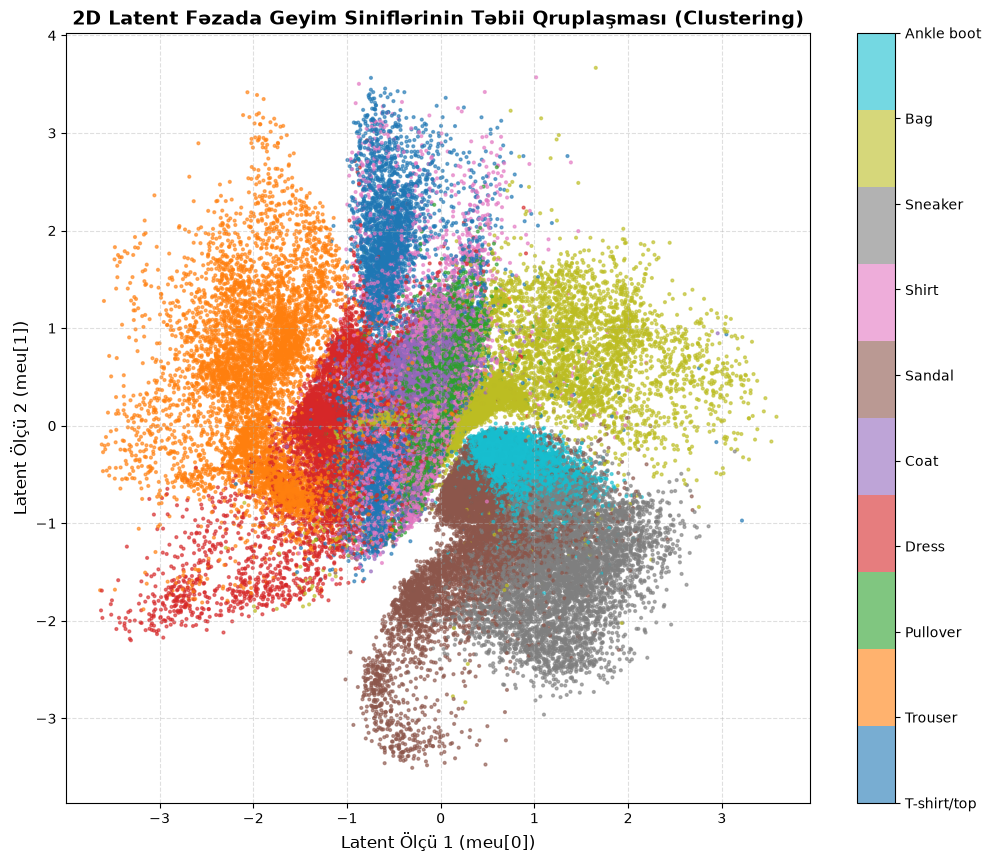

In [43]:
# Latent Fəzanın Tədqiqi və Qeyri-Nəzarətli Klasterləşdirmə (Unsupervised Clustering)
# Bütün verilənlər bazasını Encoder-dən keçirərək 2D latent fəzada paylanmasını rəngli siniflərlə vizuallaşdırırıq.
labels = np.concatenate([y_train, y_test], axis=0)
meu, _, _ = vae.encoder.predict(dataset)

plt.figure(figsize=(12, 10))
scatter = plt.scatter(meu[:, 0], meu[:, 1], c=labels, cmap="tab10", alpha=0.6, s=4)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels(class_names)
plt.title("2D Latent Fəzada Geyim Siniflərinin Təbii Qruplaşması (Clustering)", fontsize=14, fontweight="bold")
plt.xlabel("Latent Ölçü 1 (meu[0])", fontsize=12)
plt.ylabel("Latent Ölçü 2 (meu[1])", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.show();

## 🏆 Yekun Xülasə: VAE-dən Nə Öyrəndik?

1. 🔹 **Generativ Güc:** Klassik Avtoenkoderlərdən fərqli olaraq, VAE məlumatı tək nöqtə kimi deyil, **ehtimal paylanması ($\mu, \sigma$)** kimi kodlaşdırır.
2. 🔹 **Reparameterization Trick:** Təsadüfi səs-küyü ($\epsilon$) deterministik hissədən ayıraraq arxaya yayılma (*Backpropagation*) zəncirini qoruyur.
3. 🔹 **İkili Balans:** *Reconstruction Loss* şəkillərin keyfiyyətini qoruyur, *KL Divergence* isə latent fəzanı hamar və bütöv saxlayır.
4. 🔹 **Latent Fəza Manifoldu:** 2D koordinat sistemində heç bir etiket olmadan şəbəkə ayaqqabıları, çantaları və geyimləri təbii şəkildə qonşu klasterlərə ayırmağı bacarır!